# 2 · Pre-match forecasting: features, ceiling and models

**Task.** Before a match, predict each player's `player_rating` (0–10) for that match, for
players who will play at least 30 minutes. Everything the model sees must be known before
kick-off.

**Plan.**

1. build features from strictly earlier dates, and prove it;
2. estimate how much of the rating is predictable at all;
3. find which features carry that signal;
4. compare models fairly and pick one.

The heavy steps (tuning, final fits) run in `python -m player_rating.pipeline`. This notebook
explains them and loads their saved results from `reports/metrics/`.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from player_rating.checks import assert_no_future_leakage
from player_rating.config import FIGURES_DIR, METRICS_DIR
from player_rating.data import load_raw
from player_rating.features import build_feature_table
from player_rating.models.hierarchical import fit_variance_components
from player_rating.splits import assign_split, split_dates

pd.set_option("display.precision", 4)
raw = load_raw()
table = build_feature_table(raw)
train_end, validation_end = split_dates(table.loc[table["has_v1_history"], "match_date"])
table["split"] = assign_split(table["match_date"], train_end, validation_end)
table.groupby("split", sort=False)["match_date"].agg(["min", "max", "size"])

,min,max,size
split,,,
train,2026-06-11,2026-07-16,17481
validation,2026-07-17,2026-07-23,3620
test,2026-07-24,2026-07-31,4566


## 1. Features from the past only

Every feature for a match on date D is built in three steps:

1. aggregate to one row per player (or team) and date, so two matches on the same day never
   see each other;
2. shift by one date;
3. average over a window: the last 5 dates, all earlier dates, and so on.

Below are one player's first matches. The history columns of each row use only the rows above
it. Rows are matches with at least 30 minutes played; shorter appearances also count as
history.

In [2]:
history_columns = [
    "match_date",
    "player_rating",
    "n_prior_apps",
    "career_rating_mean",
    "recent_rating_mean",
    "rating_when_active_last5",
]
table.loc[table["player_id"] == "P00070", history_columns].head(8)

,match_date,player_rating,n_prior_apps,career_rating_mean,recent_rating_mean,rating_when_active_last5
495,2026-06-12,5.7,0.0,NaN,NaN,NaN
1865,2026-06-15,6.3,3.0,6.2667,6.2667,6.2667
8194,2026-06-28,5.8,5.0,6.2400,6.2400,6.3750
9097,2026-06-30,8.0,7.0,6.0429,5.9200,5.8750
9247,2026-06-30,6.5,7.0,6.0429,5.9200,5.8750
9403,2026-06-30,5.7,7.0,6.0429,5.9200,5.8750
10271,2026-07-02,6.4,8.0,6.1292,6.0467,5.9833
10813,2026-07-03,4.8,9.0,6.1593,6.0667,6.0583


The automated proof changes every outcome from a cutoff date onwards (ratings, goals, passes,
scores) and rebuilds all features. A feature that looks only at earlier dates cannot change
for any match on or before the cutoff. The same check runs in the test suite
(`tests/test_leakage.py`), and a deliberately leaky version of the code fails it.

In [3]:
checked = assert_no_future_leakage(raw, pd.Timestamp("2026-07-01"))
print(f"no leakage: features of {checked:,} player-matches up to the cutoff are unchanged")

no leakage: features of 12,566 player-matches up to the cutoff are unchanged


## 2. How much is predictable? A mixed model

The rating splits into three parts, estimated on the training weeks only:

$$\text{rating} = \underbrace{x^\top\beta}_{\text{static attributes}} +
\underbrace{u_{\text{player}}}_{\text{player's own level}} +
\underbrace{e}_{\text{match noise}}, \qquad u \sim N(0, \sigma^2_u),\; e \sim N(0, \sigma^2_e)$$

A forecaster that knew every player's true level would reach
R² = (static + player) / total variance. Nothing that is known before the match can do
better, so this is the **ceiling**.

In [4]:
components = fit_variance_components(table[table["split"] == "train"])
pd.Series(components.to_dict()).round(4).to_frame("value")

,value
static,0.1110
player,0.0488
noise,0.3851
total,0.5449
shrinkage_k,7.8931
ceiling_r2,0.2933
static_r2,0.2038


About 70% of the variance is match-to-match noise, which no pre-match model can explain. The
ceiling is R² ≈ 0.29, and static attributes alone reach ≈ 0.20. The v1 model (R² 0.24 on the
test week) was not "close to the limit": a clear gap remained.

## 3. Shrinkage: how to average a short history

Say a player has 3 matches and an average of 7.5. With this much noise, that player is
probably not a 7.5 player. The empirical-Bayes estimate combines two things:

- the player's own average, with weight n / (n + k);
- a **prior** (the usual rating for players with the same attributes, learned from training
  rows), with weight k / (n + k).

Under the mixed model above this is the best linear predictor of the player's level, with
k = σ²ₑ / σ²ᵤ. The theory says k ≈ 8, and walk-forward validation agrees:

,k,MAE,RMSE,R2
0,0.5,0.5119,0.6413,0.2509
1,1.0,0.5111,0.6401,0.2537
2,2.0,0.5101,0.6388,0.2567
3,4.0,0.5094,0.6379,0.2589
4,6.0,0.5092,0.6376,0.2595
5,8.0,0.5092,0.6376,0.2596
6,12.0,0.5093,0.6377,0.2594
7,16.0,0.5094,0.6378,0.2591
8,24.0,0.5095,0.6380,0.2586
9,32.0,0.5096,0.6382,0.2583


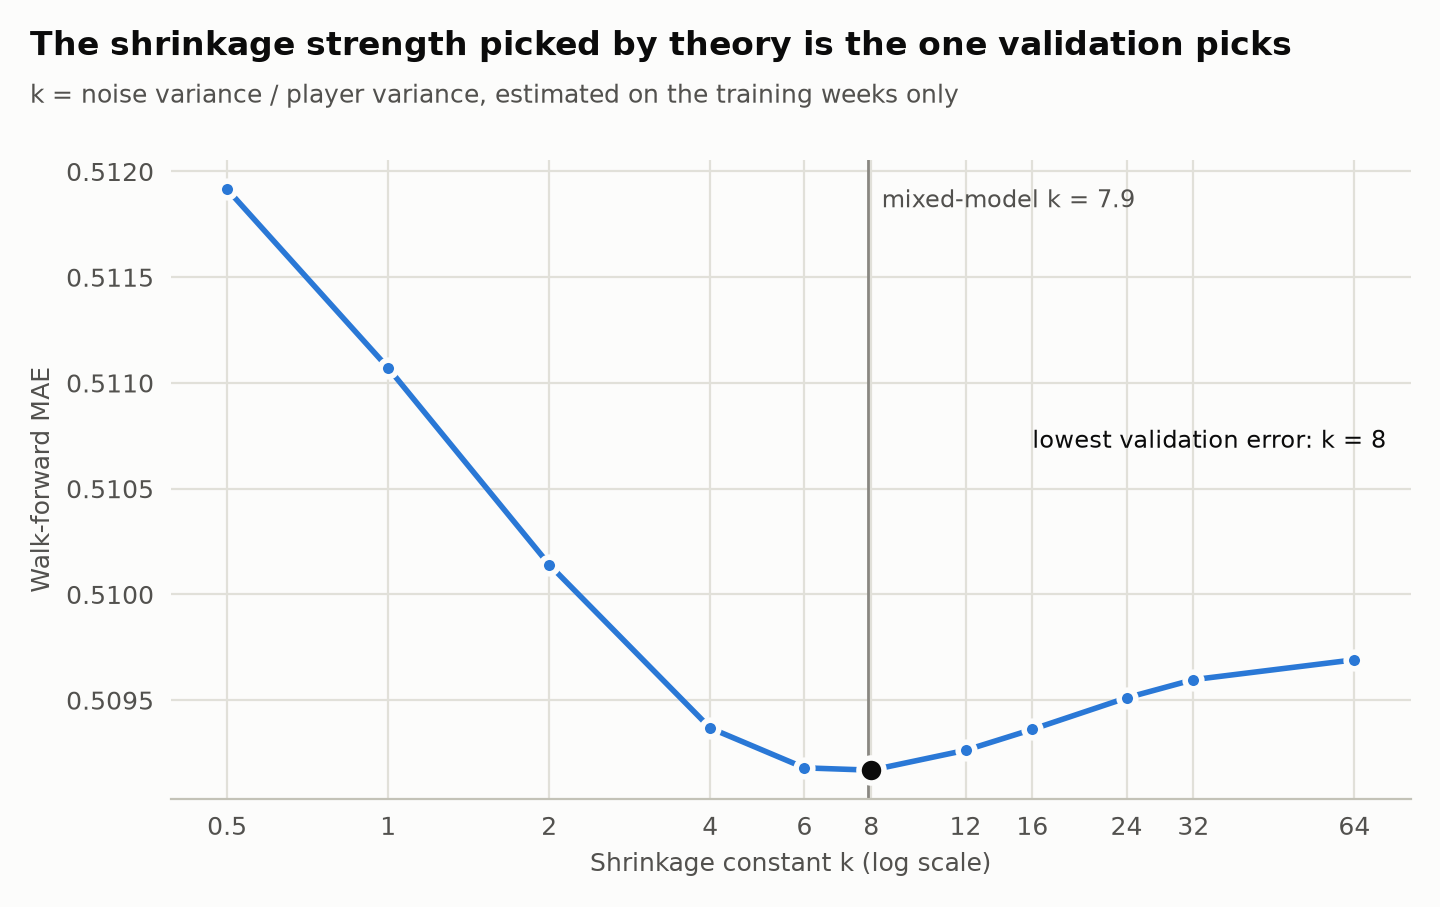

In [5]:
display(pd.read_csv(METRICS_DIR / "shrinkage_curve.csv"))
display(Image(FIGURES_DIR / "shrinkage_k_light.png", width=720))

## 4. Which features carry the signal?

Feature groups are added one at a time: ridge regression, validated walk-forward on the four
weeks before the test week.

,added group,n_inputs,MAE,RMSE,R2,MAE change,R2 change
0,static attributes,6,0.5255,0.6591,0.2080,NaN,NaN
1,recent form (shrunk),7,0.5134,0.6436,0.2448,-0.0122,0.0368
2,career level (shrunk),9,0.5089,0.6373,0.2594,-0.0044,0.0146
3,player match stats (v1),19,0.5093,0.6377,0.2586,0.0004,-0.0008
4,team form,30,0.5098,0.6385,0.2567,0.0005,-0.0019
5,opponent form,41,0.5100,0.6388,0.2560,0.0002,-0.0007
6,tournament stage,42,0.5101,0.6391,0.2554,0.0001,-0.0007


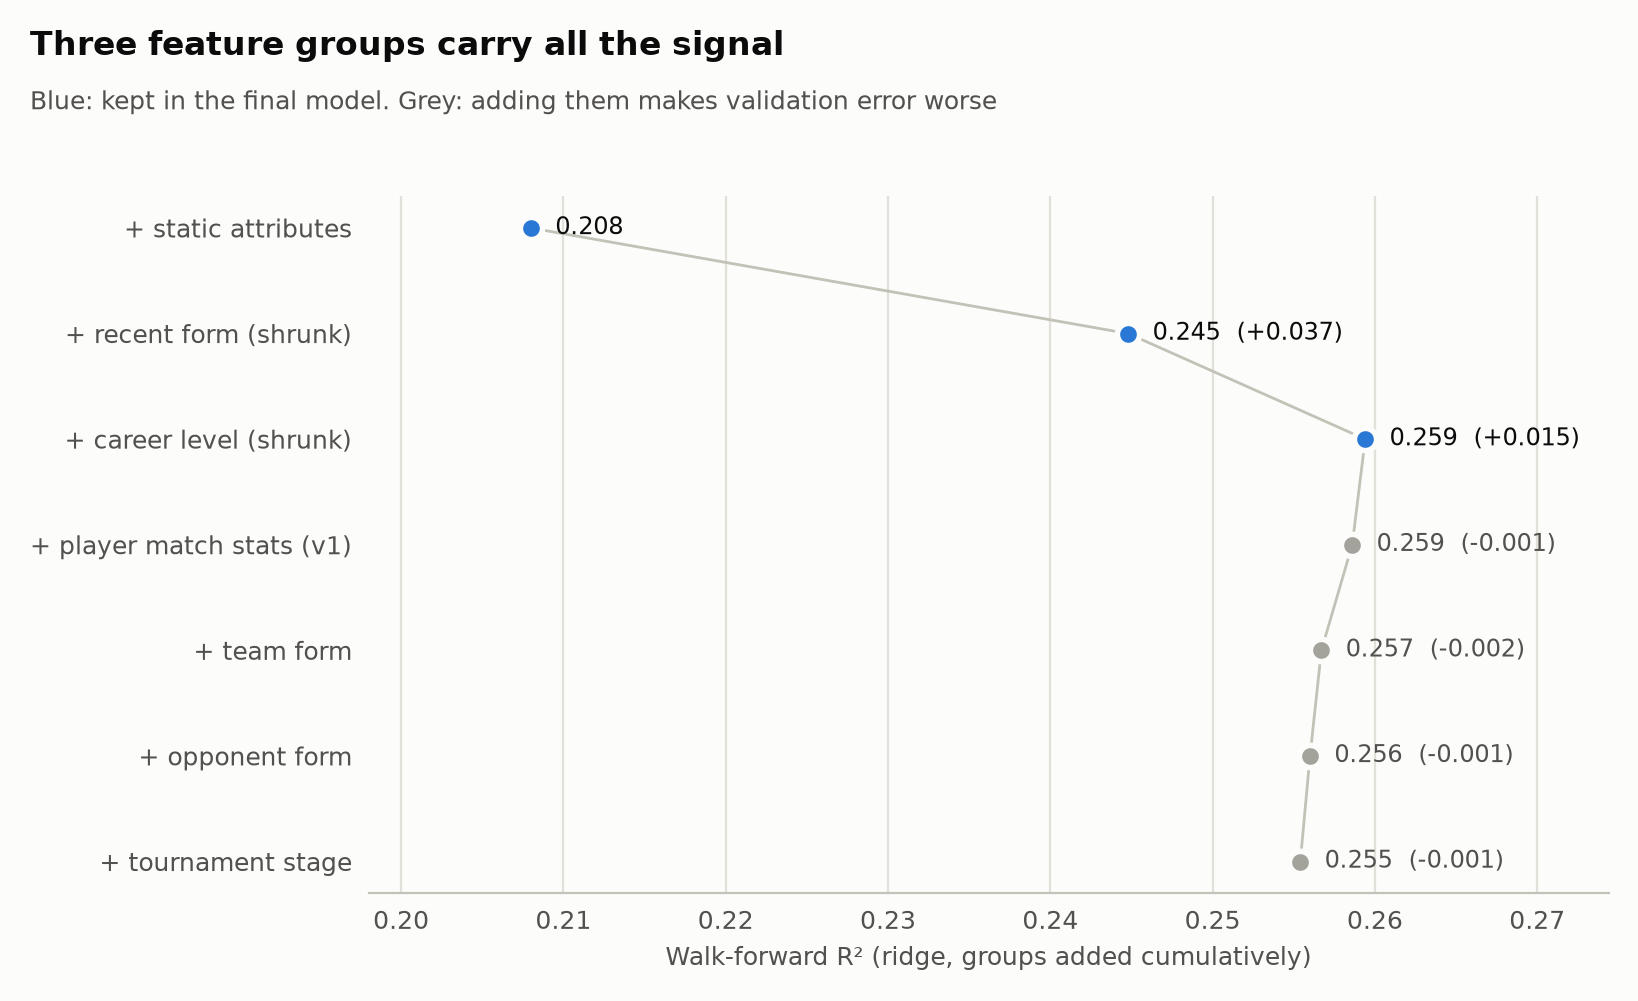

In [6]:
display(pd.read_csv(METRICS_DIR / "ablation.csv"))
display(Image(FIGURES_DIR / "ablation_light.png", width=720))

Once the player's level is estimated well, nothing else adds signal. Validation error gets
slightly worse with each of these groups:

- past goals, xG and passes;
- team form;
- opponent form;
- the tournament stage.

The v2 feature set has 9 inputs instead of the 41 of v1: static attributes, recent form (last 5
appearances, shrunk), career level (all appearances, shrunk) and the number of past
appearances.

## 5. Model comparison

The protocol is the same for every model:

- tuning with Optuna (30 trials) on the same walk-forward folds;
- a refit on train + validation, then **one** evaluation on the final test week;
- neural networks averaged over 5 seeds;
- 95% intervals from 2,000 bootstrap resamples of whole matches, because players in one match
  are not independent.

The table is evaluated on the 4,543 test rows that the v1 model could also predict.

,MAE,MAE_low,MAE_high,R2,R2_low,R2_high,dMAE,dMAE_low,dMAE_high,cv_MAE,cv_R2
model,,,,,,,,,,,
"LightGBM, v2 features",0.5039,0.4927,0.5149,0.2886,0.2652,0.3100,0.0000,0.0000,0.0000,0.5063,0.2668
"MLP, v2 features",0.5051,0.4939,0.5164,0.2842,0.2616,0.3048,0.0013,0.0002,0.0023,0.5071,0.2636
"MLP + player embedding, static features",0.5051,0.4937,0.5166,0.2839,0.2601,0.3055,0.0013,-0.0005,0.0030,0.5087,0.2600
"MLP + player embedding, v2 features",0.5055,0.4941,0.5169,0.2829,0.2607,0.3031,0.0017,0.0006,0.0028,0.5070,0.2640
"Ridge, v2 features",0.5074,0.4961,0.5189,0.2789,0.2556,0.3008,0.0036,0.0016,0.0056,0.5088,0.2597
"MLP, v1 features",0.5161,0.5043,0.5275,0.2530,0.2302,0.2727,0.0122,0.0090,0.0156,0.5178,0.2316
"Ridge, v1 features",0.5208,0.5091,0.5320,0.2433,0.2206,0.2636,0.0169,0.0131,0.0210,0.5180,0.2297
Dummy (mean),0.5989,0.5861,0.6130,-0.0000,-0.0013,-0.0000,0.0951,0.0854,0.1051,0.5890,-0.0001


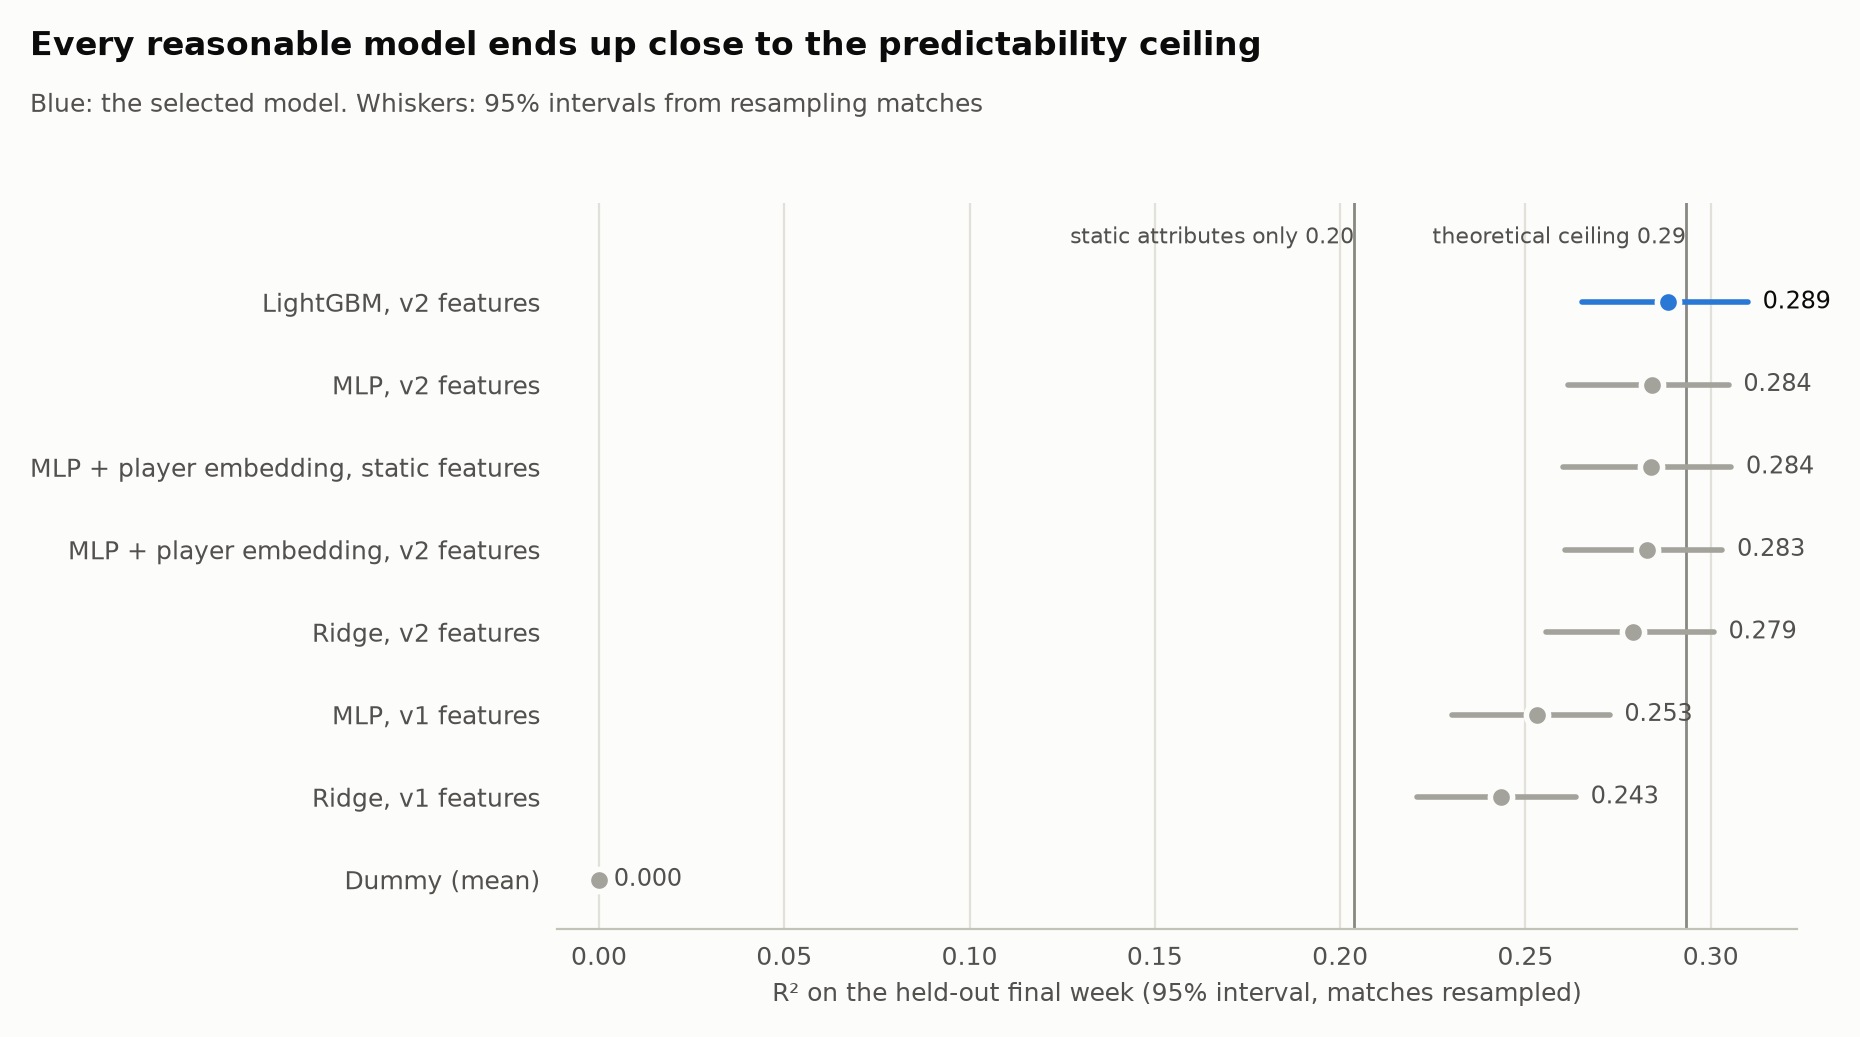

In [7]:
results = pd.read_csv(METRICS_DIR / "test_results.csv", index_col="model")
columns = [
    "MAE",
    "MAE_low",
    "MAE_high",
    "R2",
    "R2_low",
    "R2_high",
    "dMAE",
    "dMAE_low",
    "dMAE_high",
    "cv_MAE",
    "cv_R2",
]
display(results[columns].sort_values("MAE"))
display(Image(FIGURES_DIR / "model_comparison_light.png", width=720))

**Reading the table**

- **The v2 features are what matter.** With the same ridge regression, MAE drops from 0.521
  to 0.507 and R² rises from 0.243 to 0.279. The interval of the difference is far from zero.
- **Between v2 models the differences are tiny.** LightGBM is best (MAE 0.504, R² 0.289), and
  ridge is 0.0036 MAE behind it. That gap is statistically detectable (its interval excludes
  0) but practically negligible: non-linear models find a little structure that ridge
  misses, and that is all.
- **The embedding network rediscovers the player effect.** Given only static attributes and
  a learned per-player intercept, it matches the network built on hand-made history features
  (R² 0.284 for both). The embedding does the job of the shrunk career average: it is the
  mixed model's idea, learned by gradient descent.
- **The tuned embedding penalty is not the theoretical one.** Optuna picked ≈ 0.01, while the
  mixed model implies k / N ≈ 0.0004. The two are not directly comparable: with Adam, an L2
  term in the loss is weakened by the per-parameter step sizes, and early stopping
  regularises as well.
- **Selected model: LightGBM.** It has the lowest MAE, and no simpler model is statistically
  tied with it.
- **The ceiling is close.** Every v2 model lands at R² 0.28–0.29, against a ceiling of 0.293,
  so further modelling effort has almost nothing left to gain on this data.

In [8]:
reproduction = json.loads((METRICS_DIR / "v1_reproduction.json").read_text())
pd.DataFrame(
    {
        "original notebook (Ridge)": reproduction["original_notebook_test"]["Ridge"],
        "this repository (Ridge)": reproduction["ridge_test"],
        "original notebook (Keras ANN)": reproduction["original_notebook_test"]["ANN (Keras)"],
        "PyTorch port, mean of seeds": pd.DataFrame(
            reproduction["mlp_pytorch_test_per_seed"]
        ).mean(),
    }
).round(4)

,original notebook (Ridge),this repository (Ridge),original notebook (Keras ANN),"PyTorch port, mean of seeds"
MAE,0.5221,0.5221,0.5181,0.5181
RMSE,0.6538,0.6538,0.6518,0.6506
R2,0.2402,0.2402,0.2449,0.2475


The refactored pipeline reproduces the original Ridge result exactly. The PyTorch port of the
original network lands where the Keras version did, and its spread across seeds is as large as
the difference between the original ANN and Ridge. A single-seed comparison could not tell
them apart.

## 6. Where the errors are

,position,n_rows,MAE,RMSE,R2
0,Defender,1634,0.5092,0.6416,0.2533
1,Forward,1092,0.5186,0.6508,0.2888
2,Goalkeeper,374,0.4613,0.5763,0.3536
3,Midfielder,1466,0.4986,0.6239,0.2995


,history,n_rows,mean_prior_apps,RMSE,expected_RMSE
0,0,8,0.0000,0.3740,0.6587
1,1-2,78,1.7692,0.6292,0.6519
2,3-5,1195,4.3615,0.6243,0.6455
3,6-10,5404,8.1323,0.6378,0.6398
4,11-15,4963,12.8289,0.6318,0.6354
5,16-20,2088,17.3918,0.6379,0.6327
6,21-30,304,22.2862,0.6441,0.6308


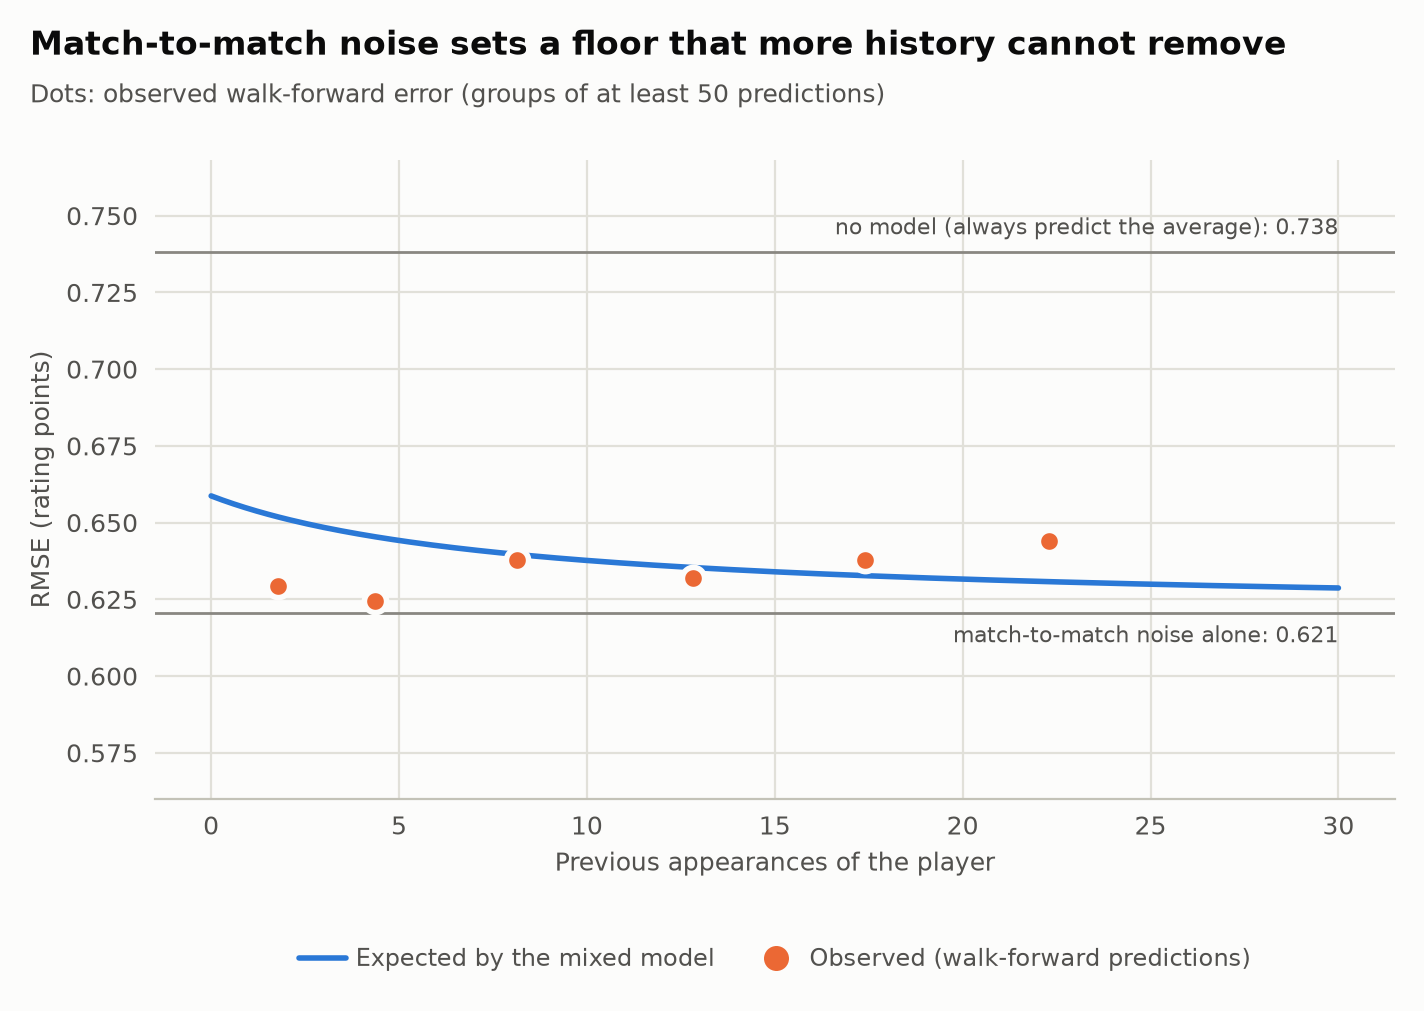

In [9]:
display(pd.read_csv(METRICS_DIR / "error_by_position.csv"))
display(pd.read_csv(METRICS_DIR / "error_by_history_walk_forward.csv"))
display(Image(FIGURES_DIR / "error_vs_history_light.png", width=720))

- **By position:** goalkeepers are the most predictable (MAE 0.46, R² 0.35), and forwards
  have the largest errors (MAE 0.52).
- **By history:** the observed error stays between 0.62 and 0.65 whatever the number of
  previous appearances. That is just above the match-noise floor of 0.62 and far below the
  0.74 of always predicting the average. The decline the mixed model expects (0.65 → 0.63)
  is too small to separate from week-to-week variation. In practice, a handful of matches
  plus the market-value prior pin a player's level down about as well as this noise allows.

## Conclusions

1. About 71% of the rating is match noise, so no pre-match model can go beyond R² ≈ 0.29.
2. A statistically principled feature, the empirical-Bayes estimate of the player's level, is
   worth more than 32 extra hand-made features, and more than switching model families.
3. Ridge, gradient boosting and neural networks all land within 0.004 MAE of each other, near
   the ceiling. LightGBM is selected. The network with player embeddings reaches the same
   accuracy without any history features.
4. Most of the remaining error cannot be removed, so the useful next step is honest
   uncertainty rather than more accuracy: see `03_uncertainty.ipynb`.